##Exemplo Agrupamento (Clustering) em Machine Learning

Diferente dos problemas de **Classificação** e **Regressão**, não temos uma **resposta pronta** (rótulo $y$). O nosso **objetivo** é fazer com que a máquina encontre **estruturas** e **grupos** naturais **ocultos** nos dados.

Nesta aula prática, vamos aplicar algoritmos de **Aprendizado Não Supervisionado** em um dataset do **Kaggle**: **Mall Customer Segmentation Data** (Base de Clientes de um Shopping Center).

**Objetivo Prático**: Agrupar os clientes com base no seu **perfil financeiro** e **comportamental** — especificamente utilizando a **Renda Anual** (Annual Income in k$) e a **Pontuação de Gastos** (Spending Score, de 1 a 100) — para auxiliar a equipe de marketing a criar estratégias direcionadas sem depender de rótulos prévios.

In [9]:
# Pandas: Biblioteca para manipulação, filtragem e organização de tabelas de dados (DataFrames).
import pandas as pd

# NumPy: Biblioteca para operações matemáticas e vetoriais de alta performance.
import numpy as np

# Matplotlib e Seaborn: Ferramentas para geração de gráficos estatísticos e visualizações de dados.
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn: Principal biblioteca de Machine Learning em Python.
# Importamos os três algoritmos de agrupamento que estudaremos nesta aula:
from sklearn.cluster import KMeans                   # Agrupamento baseado em Centroides
from sklearn.cluster import AgglomerativeClustering  # Agrupamento Hierárquico Aglomerativo
from sklearn.cluster import DBSCAN                   # Agrupamento baseado em Densidade com Detecção de Ruído

# Scipy: Biblioteca científica usada para gerar o Dendrograma do agrupamento hierárquico.
import scipy.cluster.hierarchy as sch

# StandardScaler: Ferramenta que padroniza a escala das variáveis (Média = 0, Desvio Padrão = 1).
# Isso impede que uma coluna numericamente maior domine os cálculos de distância geométrica.
from sklearn.preprocessing import StandardScaler

# Warnings: Silencia mensagens de alerta do Python relacionadas a atualizações de versões para manter a saída limpa.
import warnings
warnings.filterwarnings('ignore')

# Configuração global de estilo dos gráficos para melhor legibilidade
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 11

##1. Carregamento dos Dados Reais (Kaggle)

Utilizaremos o dataset **Mall Customers**, amplamente utilizado em projetos de ciência de dados para segmentação de mercado.

In [10]:
# pd.read_csv(): Lê o arquivo em formato CSV diretamente de um repositório público no GitHub (origem do Kaggle)
# e o carrega em uma estrutura de tabela (DataFrame).
url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
df = pd.read_csv(url)

# df.columns: Renomeia as colunas originais em inglês para o português, facilitando a interpretação.
df.columns = ['ID_Cliente', 'Genero', 'Idade', 'Renda_Anual_k$', 'Pontuacao_Gastos_1_100']

# display(df.head()): Exibe as 5 primeiras linhas da tabela para conferirmos o formato dos dados carregados.
print("Primeiras 5 linhas da tabela de clientes:")
display(df.head())

# df.info(): Exibe o número total de linhas (200 clientes), tipos de dados de cada coluna e confirma ausência de valores nulos.
print("\nEstrutura e informações gerais dos dados:")
df.info()

Primeiras 5 linhas da tabela de clientes:


,ID_Cliente,Genero,Idade,Renda_Anual_k$,Pontuacao_Gastos_1_100
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Estrutura e informações gerais dos dados:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   ID_Cliente              200 non-null    int64 
 1   Genero                  200 non-null    object
 2   Idade                   200 non-null    int64 
 3   Renda_Anual_k$          200 non-null    int64 
 4   Pontuacao_Gastos_1_100  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


##2. Visualização Inicial dos Dados

Vamos analisar a distribuição espacial dos clientes comparando a **Renda Anual** com a **Pontuação de Gastos**.

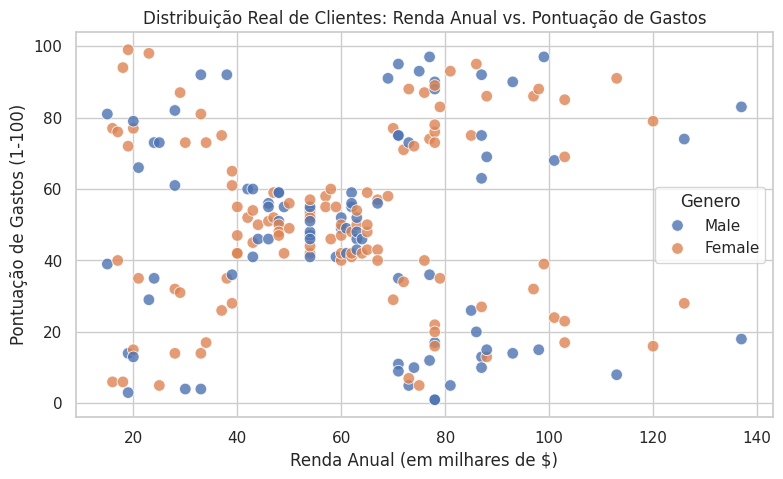

In [11]:
# plt.figure(): Define o tamanho do quadro do gráfico em polegadas (largura x altura).
plt.figure(figsize=(9, 5))

# sns.scatterplot(): Desenha o gráfico de dispersão onde cada ponto representa 1 cliente.
# x='Renda_Anual_k$': Posição no eixo horizontal (Renda em milhares de dólares).
# y='Pontuacao_Gastos_1_100': Posição no eixo vertical (Score de gastos de 1 a 100).
# hue='Genero': Colore os pontos de acordo com o sexo do cliente para observar se há padrão por gênero.
sns.scatterplot(
    data=df,
    x='Renda_Anual_k$',
    y='Pontuacao_Gastos_1_100',
    hue='Genero',
    s=70,
    alpha=0.8
)

# Adiciona título e rótulos aos eixos do gráfico.
plt.title("Distribuição Real de Clientes: Renda Anual vs. Pontuação de Gastos")
plt.xlabel("Renda Anual (em milhares de $)")
plt.ylabel("Pontuação de Gastos (1-100)")
plt.show()

##3. Pré-processamento: Seleção de Atributos e Escalonamento
Para que os algoritmos consigam calcular **distâncias geométricas** de maneira justa (evitando que uma variável em escala maior domine a medição), aplicamos a **padronização** (StandardScaler).

In [12]:
# Selecionamos apenas as duas colunas numéricas que definem o perfil financeiro/comportamental.
X = df[['Renda_Anual_k$', 'Pontuacao_Gastos_1_100']]

# Instanciamos o objeto de padronização.
scaler = StandardScaler()

# .fit_transform():
# 1. 'fit' calcula a média e o desvio padrão de cada coluna.
# 2. 'transform' aplica a fórmula z = (x - média) / desvio_padrão em todos os valores.
# O resultado (X_scaled) é um array NumPy onde ambas as colunas passam a ter média = 0 e desvio padrão = 1.
X_scaled = scaler.fit_transform(X)

print("Estrutura das duas primeiras linhas dos dados padronizados (escala ajustada):")
print(X_scaled[:2])

Estrutura das duas primeiras linhas dos dados padronizados (escala ajustada):
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]]


##4. Modelo 1: K-Means (Com Método do Cotovelo / Elbow Method)
O K-Means particiona os dados em $K$ grupos esféricos ao redor de centroides. Utilizaremos a curva de inércia (Método do Cotovelo) para determinar visualmente a quantidade ideal de grupos.

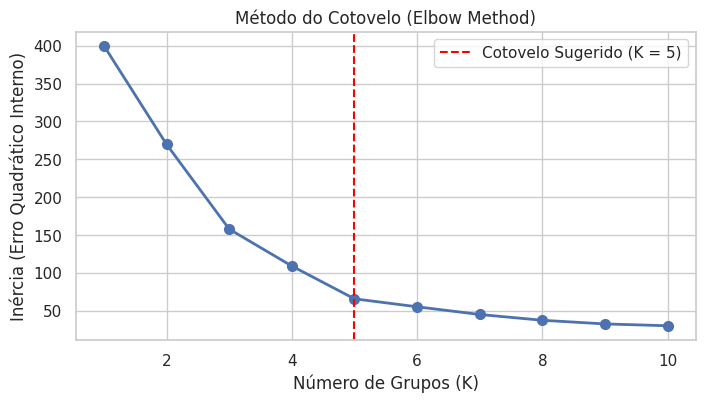

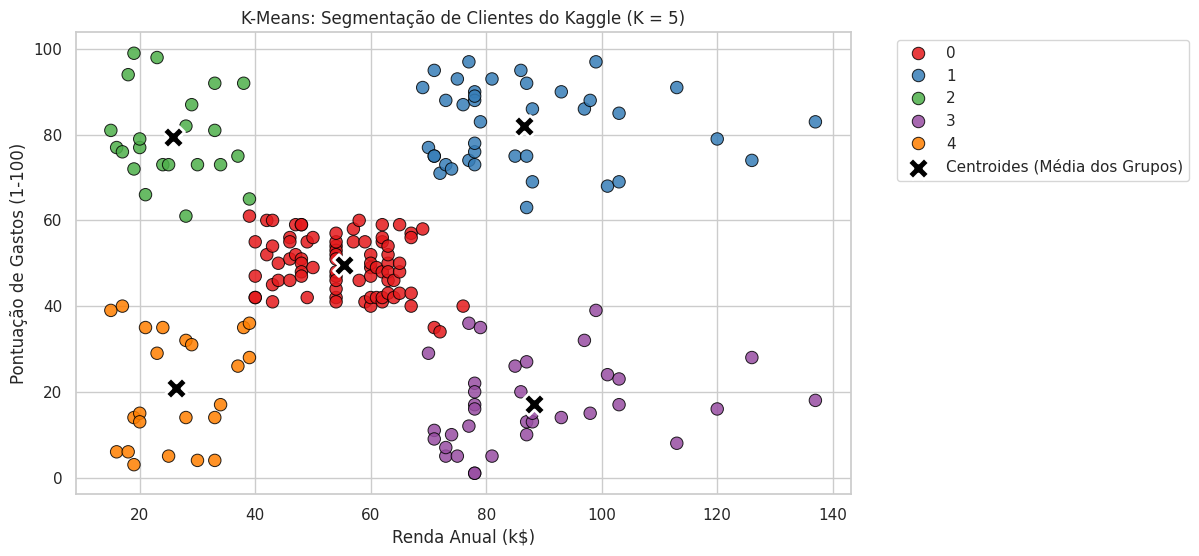

In [13]:
# --- PASSO 1: Descobrir a quantidade ideal de grupos (K) ---
inercias = []
faixa_k = range(1, 11)  # Testaremos de 1 a 10 grupos

# O laço roda o K-Means para cada valor de K e guarda a Inércia (Soma dos erros quadráticos internos).
for k in faixa_k:
    # n_init=10: Executa o algoritmo 10 vezes com centroides iniciais aleatórios diferentes e mantém o melhor resultado.
    kmeans_teste = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_teste.fit(X_scaled)
    inercias.append(kmeans_teste.inertia_)  # .inertia_: Mede o quão compactos estão os grupos

# Plotagem da curva do Método do Cotovelo
plt.figure(figsize=(8, 4))
plt.plot(faixa_k, inercias, 'bo-', linewidth=2, markersize=7)
plt.title("Método do Cotovelo (Elbow Method)")
plt.xlabel("Número de Grupos (K)")
plt.ylabel("Inércia (Erro Quadrático Interno)")
# Desenha uma linha vermelha tracejada no ponto de inflexão/dobra da curva (K = 5).
plt.axvline(x=5, color='red', linestyle='--', label='Cotovelo Sugerido (K = 5)')
plt.legend()
plt.show()

# --- PASSO 2: Treinamento do K-Means com K=5 ---
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# .fit_predict(): Treina o modelo com os dados padronizados e retorna o número do grupo (0 a 4) atribuído a cada cliente.
df['Cluster_KMeans'] = kmeans.fit_predict(X_scaled)

# .cluster_centers_: Retorna as coordenadas dos 5 centroides no espaço padronizado.
# .inverse_transform(): Converte as coordenadas dos centroides de volta para a escala original (em dólares e score de gastos).
centroides_originais = scaler.inverse_transform(kmeans.cluster_centers_)

# --- PASSO 3: Plotagem dos Grupos e Centroides ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Renda_Anual_k$',
    y='Pontuacao_Gastos_1_100',
    hue='Cluster_KMeans',
    palette='Set1',
    s=80,
    alpha=0.85,
    edgecolor='black'
)

# Desenha os marcadores dos centroides (X pretos grandes com borda branca) no centro exato de cada grupo.
plt.scatter(
    centroides_originais[:, 0],
    centroides_originais[:, 1],
    s=250,
    c='black',
    marker='X',
    label='Centroides (Média dos Grupos)',
    edgecolor='white',
    linewidth=2
)

plt.title("K-Means: Segmentação de Clientes do Kaggle (K = 5)")
plt.xlabel("Renda Anual (k$)")
plt.ylabel("Pontuação de Gastos (1-100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#5. Modelo 2: Agrupamento Hierárquico Aglomerativo (Dendrograma)
Este modelo conecta os clientes passo a passo de baixo para cima. O Dendrograma permite tomar a decisão visual da altura de corte dos grupos sem suposições prévias.

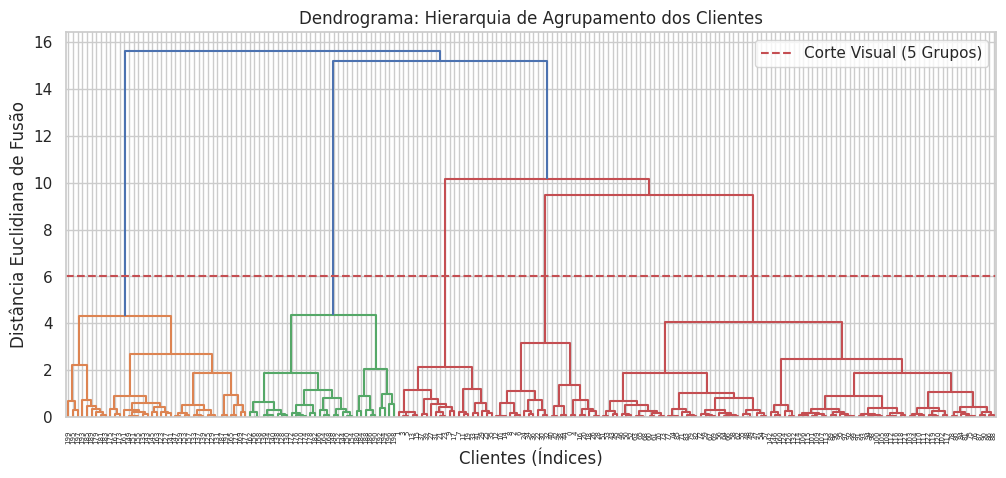

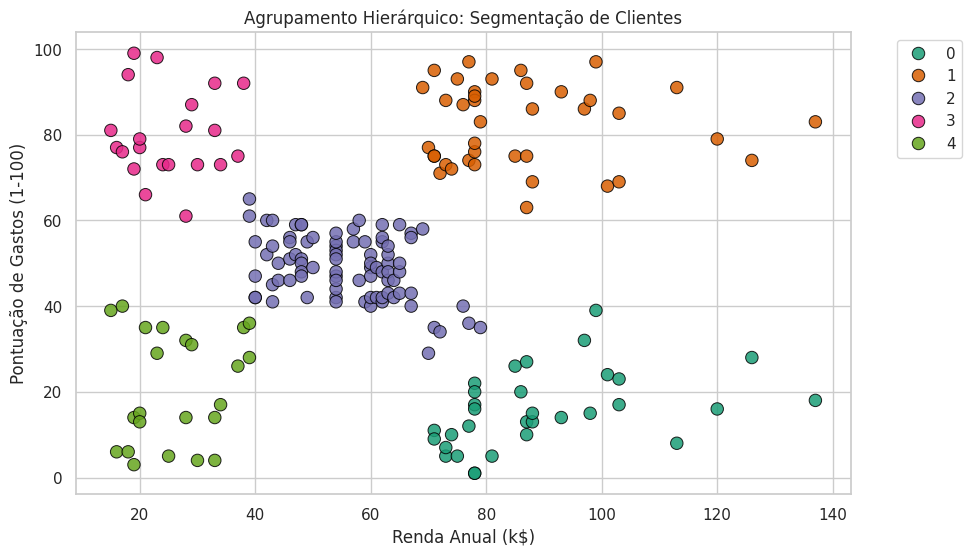

In [14]:
# --- PASSO 1: Construção e Exibição do Dendrograma ---
plt.figure(figsize=(12, 5))

# sch.linkage(): Calcula a matriz de distâncias de fusão hierárquica.
# method='ward': Minimiza a variância total dentro dos grupos a cada etapa de fusão.
matriz_ligacao = sch.linkage(X_scaled, method='ward')

# sch.dendrogram(): Desenha a estrutura da árvore de conexões de todos os 200 clientes.
dendrograma = sch.dendrogram(matriz_ligacao)

plt.title("Dendrograma: Hierarquia de Agrupamento dos Clientes")
plt.xlabel("Clientes (Índices)")
plt.ylabel("Distância Euclidiana de Fusão")
# Desenha uma linha horizontal no nível de corte que gera 5 grupos verticais distintos.
plt.axhline(y=6.0, color='r', linestyle='--', label='Corte Visual (5 Grupos)')
plt.legend()
plt.show()

# --- PASSO 2: Ajuste do Algoritmo Hierárquico com 5 Grupos ---
hierarquico = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')

# .fit_predict(): Atribui a cada cliente o rótulo do seu grupo na árvore.
df['Cluster_Hierarquico'] = hierarquico.fit_predict(X_scaled)

# --- PASSO 3: Plotagem dos Grupos Resultantes ---
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Renda_Anual_k$',
    y='Pontuacao_Gastos_1_100',
    hue='Cluster_Hierarquico',
    palette='Dark2',
    s=80,
    alpha=0.85,
    edgecolor='black'
)

plt.title("Agrupamento Hierárquico: Segmentação de Clientes")
plt.xlabel("Renda Anual (k$)")
plt.ylabel("Pontuação de Gastos (1-100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

##6. Modelo 3: DBSCAN (Grupos por Densidade + Detecção de Outliers)
O DBSCAN busca regiões com alta concentração de clientes e identifica automaticamente clientes isolados ou atípicos, marcando-os como Ruído / Outlier (Rótulo = -1).

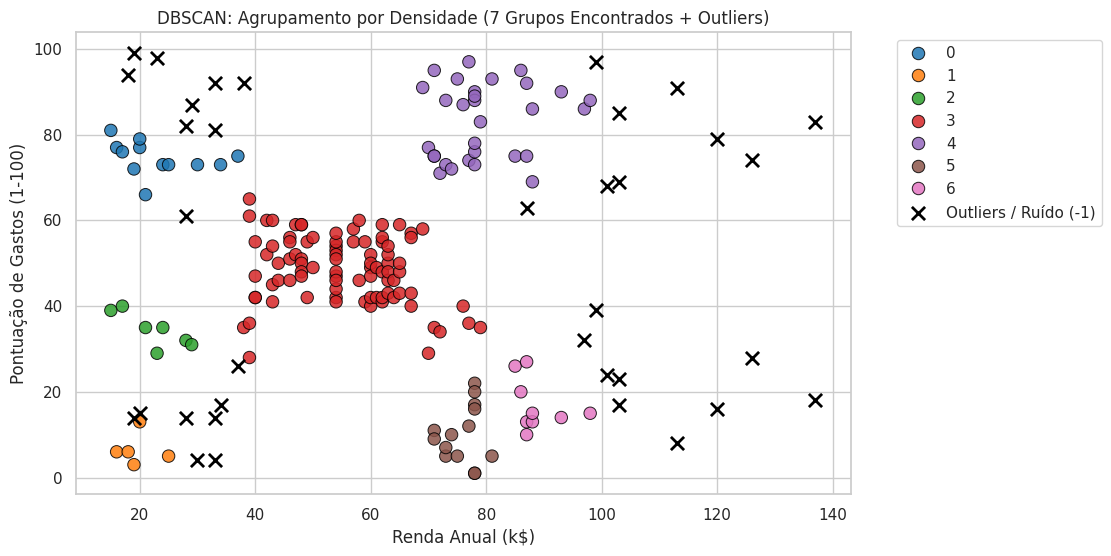

In [15]:
# --- PASSO 1: Configuração e Ajuste do DBSCAN ---
# eps=0.3: Raio do círculo de vizinhança na escala padronizada.
# min_samples=5: Mínimo de clientes dentro do raio eps para formar uma região densa (Ponto Central).
dbscan = DBSCAN(eps=0.3, min_samples=5)

# .fit_predict(): Identifica grupos por densidade e atribui -1 para os pontos considerados ruído/outliers.
df['Cluster_DBSCAN'] = dbscan.fit_predict(X_scaled)

# --- PASSO 2: Separação dos Grupos Válidos vs. Pontos de Ruído ---
# Pontos com rótulo diferente de -1 pertencem a grupos densos normais.
validos = df[df['Cluster_DBSCAN'] != -1]
# Pontos com rótulo igual a -1 são os outliers isolados no espaço.
ruidos = df[df['Cluster_DBSCAN'] == -1]

# --- PASSO 3: Plotagem dos Grupos e Destaque dos Ruídos ---
plt.figure(figsize=(10, 6))

# Plota os clientes pertencentes aos grupos densos normais com cores variadas.
sns.scatterplot(
    data=validos,
    x='Renda_Anual_k$',
    y='Pontuacao_Gastos_1_100',
    hue='Cluster_DBSCAN',
    palette='tab10',
    s=80,
    alpha=0.85,
    edgecolor='black'
)

# Plota explicitamente os pontos de Ruído/Outlier como 'X' pretos destacados.
plt.scatter(
    ruidos['Renda_Anual_k$'],
    ruidos['Pontuacao_Gastos_1_100'],
    c='black',
    marker='x',
    s=90,
    linewidth=2,
    label='Outliers / Ruído (-1)'
)

# Calcula quantos grupos válidos foram encontrados automaticamente (desconsiderando o rótulo -1 de ruído).
qtd_grupos = len(set(df['Cluster_DBSCAN'])) - (1 if -1 in df['Cluster_DBSCAN'].values else 0)

plt.title(f"DBSCAN: Agrupamento por Densidade ({qtd_grupos} Grupos Encontrados + Outliers)")
plt.xlabel("Renda Anual (k$)")
plt.ylabel("Pontuação de Gastos (1-100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

##7. Comparativo Geral Visual dos 3 Modelos
Para finalizar, visualizamos o resultado da segmentação dos três algoritmos lado a lado na base real do Kaggle.

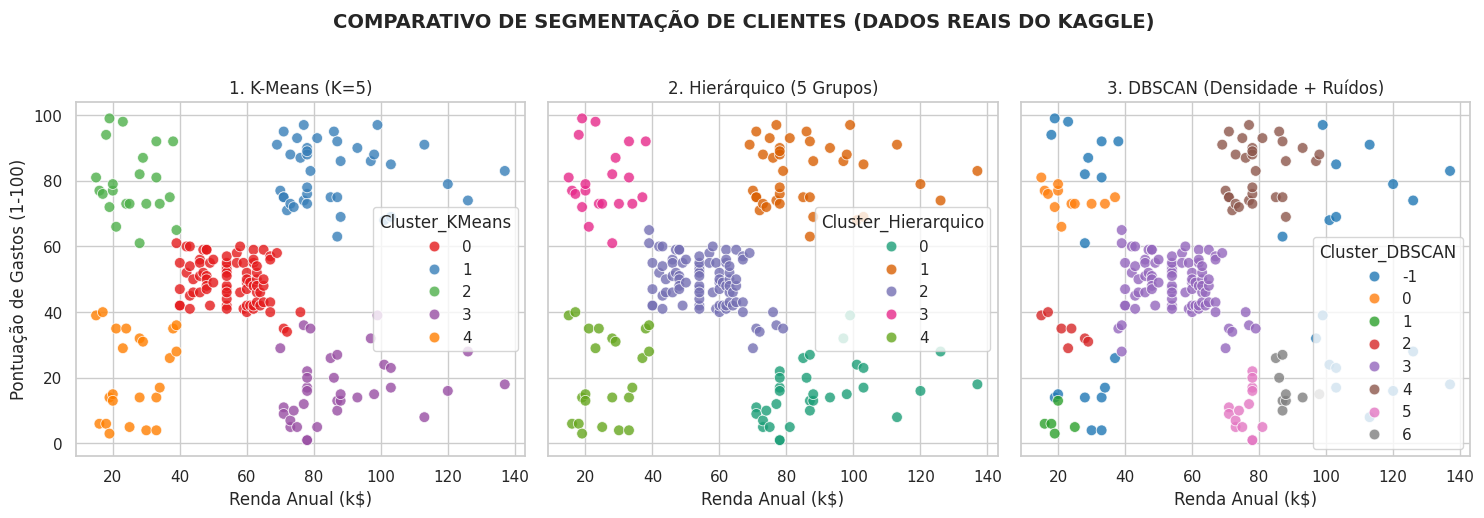

In [26]:
# plt.subplots(1, 3): Cria uma figura contendo 1 linha e 3 colunas de gráficos lado a lado.
# sharey=True: Mantém o eixo vertical na mesma escala para facilitação de comparação visual.
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

# ------------------------------------------------------------------------------
# Subplot 1: Resultado do K-Means (Grupos Esféricos ao redor de Centroides)
# ------------------------------------------------------------------------------
sns.scatterplot(
    ax=axes[0], data=df, x='Renda_Anual_k$', y='Pontuacao_Gastos_1_100',
    hue='Cluster_KMeans', palette='Set1', s=60, alpha=0.8
)
axes[0].set_title("1. K-Means (K=5)")
axes[0].set_xlabel("Renda Anual (k$)")
axes[0].set_ylabel("Pontuação de Gastos (1-100)")

# ------------------------------------------------------------------------------
# Subplot 2: Resultado do Agrupamento Hierárquico (Fusão Sequencial via Dendrograma)
# ------------------------------------------------------------------------------
sns.scatterplot(
    ax=axes[1], data=df, x='Renda_Anual_k$', y='Pontuacao_Gastos_1_100',
    hue='Cluster_Hierarquico', palette='Dark2', s=60, alpha=0.8
)
axes[1].set_title("2. Hierárquico (5 Grupos)")
axes[1].set_xlabel("Renda Anual (k$)")

# ------------------------------------------------------------------------------
# Subplot 3: Resultado do DBSCAN (Regiões Densas + Tratamento de Outliers em Preto)
# ------------------------------------------------------------------------------
sns.scatterplot(
    ax=axes[2], data=df, x='Renda_Anual_k$', y='Pontuacao_Gastos_1_100',
    hue='Cluster_DBSCAN', palette='tab10', s=60, alpha=0.8
)
axes[2].set_title("3. DBSCAN (Densidade + Ruídos)")
axes[2].set_xlabel("Renda Anual (k$)")

# Título geral centralizado acima dos 3 gráficos
plt.suptitle("COMPARATIVO DE SEGMENTAÇÃO DE CLIENTES (DADOS REAIS DO KAGGLE)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()